# Lecture 7: Targeting the Right Customers
## Predictive Targeting with the UCI Bank Marketing Dataset

---

### Learning Objectives

By completing this notebook you will be able to:

1. Explore a real-world bank marketing dataset and visualise relationships between customer features and subscription behaviour
2. Prepare data for modelling: handle categorical variables, drop leaky features, engineer feature groups
3. Perform model selection using cross-validation across meaningful feature group strategies
4. Fit and interpret a logistic regression model using statsmodels
5. Evaluate classification performance using confusion matrices, ROC curves, and AUC
6. Build and interpret lift charts to determine optimal targeting depth
7. Compare logistic regression with XGBoost and design a data-driven targeting strategy

### Dataset

We use the **UCI Bank Marketing dataset** (41,188 records) from direct marketing campaigns (phone calls) of a Portuguese banking institution.

| Group | Variable | Type | Description |
|-------|----------|------|-------------|
| **Demographics** | `age` | Numeric | Client age in years |
| | `job` | Categorical | Occupation (admin., blue-collar, technician, ...) |
| | `marital` | Categorical | Marital status (married, single, divorced) |
| | `education` | Categorical | Education level (basic.4y, high.school, university.degree, ...) |
| **Financial** | `default` | Categorical | Has credit in default? (yes, no, unknown) |
| | `housing` | Categorical | Has a housing loan? (yes, no) |
| | `loan` | Categorical | Has a personal loan? (yes, no) |
| **Campaign** | `contact` | Categorical | Contact type (cellular, telephone) |
| | `month` | Categorical | Last contact month |
| | `day_of_week` | Categorical | Last contact day of week |
| | `duration` | Numeric | Last contact duration in seconds (**will be dropped — data leakage**) |
| | `campaign` | Numeric | Number of contacts during this campaign |
| | `pdays` | Numeric | Days since last contact from previous campaign (999 = never contacted) |
| | `previous` | Numeric | Number of contacts before this campaign |
| | `poutcome` | Categorical | Outcome of previous campaign (success, failure, nonexistent) |
| **Economic** | `emp.var.rate` | Numeric | Employment variation rate (quarterly) |
| | `cons.price.idx` | Numeric | Consumer price index (monthly) |
| | `cons.conf.idx` | Numeric | Consumer confidence index (monthly) |
| | `euribor3m` | Numeric | Euribor 3-month rate (daily) |
| | `nr.employed` | Numeric | Number of employees (quarterly) |
| **Target** | `y` | Binary | Did the client subscribe to a term deposit? (yes/no) |

---
## 0. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import KFold
from sklearn.metrics import confusion_matrix, accuracy_score, roc_curve, roc_auc_score
from xgboost import XGBClassifier
import warnings

warnings.filterwarnings('ignore')

DATA_PATH = '../data/bank_marketing.csv'

---
## 1. Load and Explore the Data

### Task 1.1: Load the dataset

Load `bank_marketing.csv` into a DataFrame. Note that the file uses **semicolons** as separators (`sep=';'`). Display the shape, first few rows, and the distribution of the target variable `y`.

In [2]:
df = pd.read_csv(DATA_PATH, sep=';')
print(df.shape)
print(df.y.value_counts(normalize=True).round(3))
df.head()

(41188, 21)
y
no     0.887
yes    0.113
Name: proportion, dtype: float64


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Task 1.2: Summary statistics

Examine summary statistics for numeric and categorical columns. Also count how many "unknown" values exist in each column.

**Hint:** Use `df.describe()` for numerics and `df.describe(include='object')` for categoricals. Loop through object columns and count where values equal `'unknown'`.

In [3]:
display(df.describe().round(2), df.describe(include='object'))
unknowns = {col: (df[col] == 'unknown').sum() for col in df.select_dtypes('object')}
pd.Series(unknowns)[lambda s: s > 0]

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00,41188.00
mean,40.02,258.29,2.57,962.48,0.17,0.08,93.58,-40.50,3.62,5167.04
std,10.42,259.28,2.77,186.91,0.49,1.57,0.58,4.63,1.73,72.25
min,17.00,0.00,1.00,0.00,0.00,-3.40,92.20,-50.80,0.63,4963.60
25%,32.00,102.00,1.00,999.00,0.00,-1.80,93.08,-42.70,1.34,5099.10
50%,38.00,180.00,2.00,999.00,0.00,1.10,93.75,-41.80,4.86,5191.00
75%,47.00,319.00,3.00,999.00,0.00,1.40,93.99,-36.40,4.96,5228.10
max,98.00,4918.00,56.00,999.00,7.00,1.40,94.77,-26.90,5.04,5228.10


,job,marital,education,default,housing,loan,contact,month,day_of_week,poutcome,y
count,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188,41188
unique,12,4,8,3,3,3,2,10,5,3,2
top,admin.,married,university.degree,no,yes,no,cellular,may,thu,nonexistent,no
freq,10422,24928,12168,32588,21576,33950,26144,13769,8623,35563,36548


job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

### Task 1.3: Visualise the target variable

Create a bar plot showing the distribution of the target variable `y`. Use `color=['orange', 'green']`.

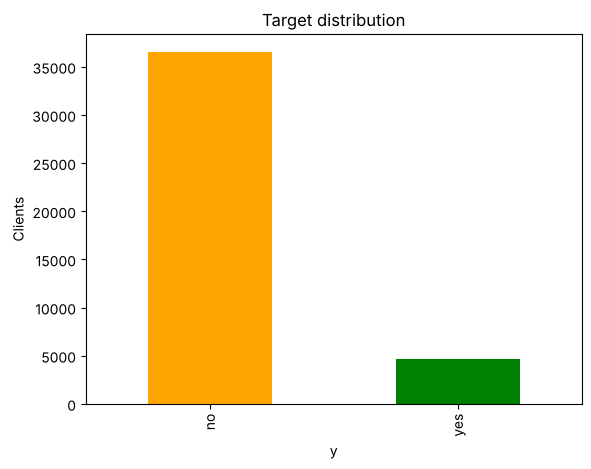

In [4]:
df.y.value_counts().plot(kind='bar', color=['orange', 'green'])
plt.title('Target distribution'); plt.ylabel('Clients'); plt.show()

### Task 1.4: Subscription rate by job

Create a horizontal bar plot showing the subscription rate for each job category, sorted by rate.

**Hint:** Use `pd.crosstab(df['job'], df['y'], normalize='index') * 100` to get percentages.

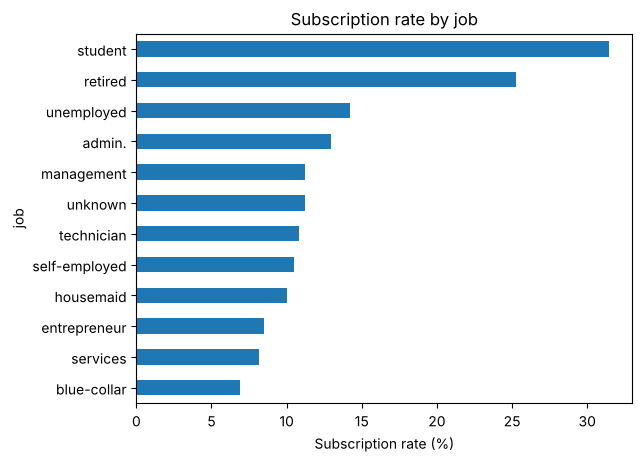

In [5]:
rate = lambda col: (pd.crosstab(df[col], df.y, normalize='index') * 100)['yes'].sort_values()
rate('job').plot(kind='barh')
plt.xlabel('Subscription rate (%)'); plt.title('Subscription rate by job'); plt.show()

### Task 1.5: Subscription rate by previous outcome and contact type

Create side-by-side bar plots showing subscription rates for `poutcome` and `contact`.

**Hint:** Use `fig, axes = plt.subplots(1, 2, figsize=(14, 6))` for side-by-side plots.

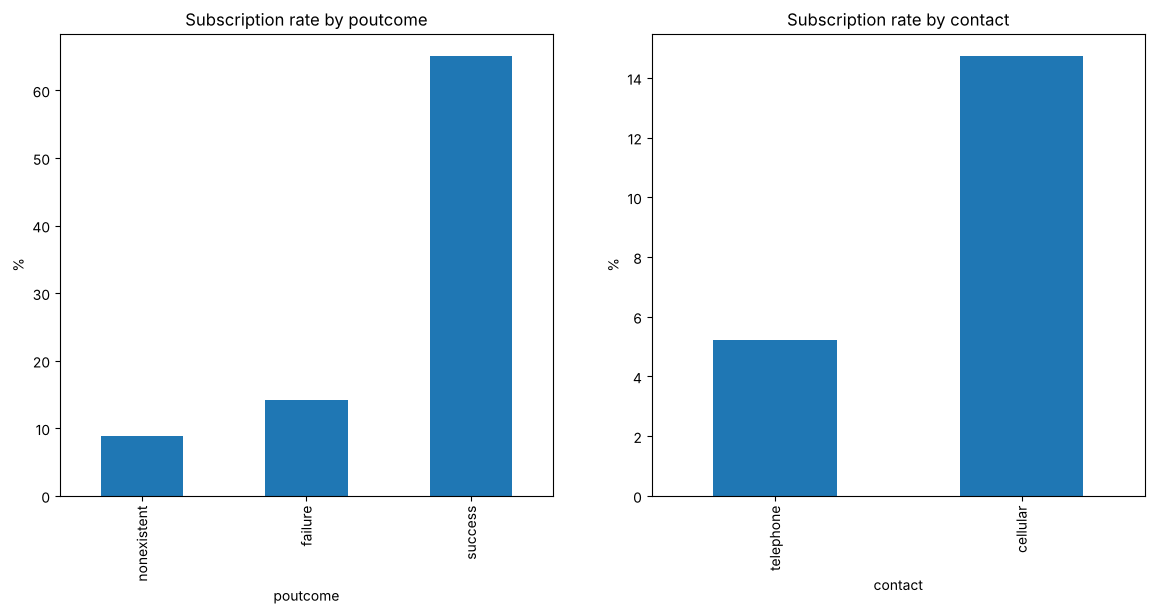

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, col in zip(axes, ['poutcome', 'contact']):
    rate(col).plot(kind='bar', ax=ax, title=f'Subscription rate by {col}', ylabel='%')
plt.show()

### Task 1.6: Numeric features by subscription status

Create boxplots of `age` and `euribor3m` grouped by subscription status.

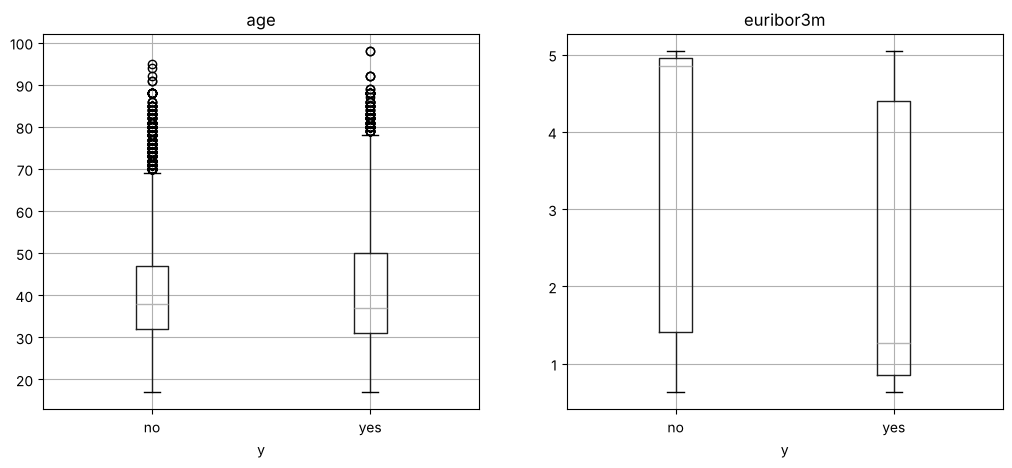

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, col in zip(axes, ['age', 'euribor3m']):
    df.boxplot(column=col, by='y', ax=ax)
plt.suptitle(''); plt.show()

### Discussion

**Answer the following:**
- How imbalanced is the target variable? Why does this matter for modelling?
- Which job categories have the highest subscription rates?
- What is the subscription rate when the previous campaign outcome was "success"? What does this imply?
- Why must the `duration` column be excluded from a realistic predictive model?

- **Imbalance:** very imbalanced. Only 11.3% subscribe. A model that always says "no" gets 89% accuracy and is useless, so accuracy fools you. Look at sensitivity, AUC and lift.
- **Jobs:** students (31%) and retirees (25%) lead by far, followed by unemployed (14%) and admin (13%). Blue-collar (7%) and services (8%) come last. That matches age: under-25s and over-60s subscribe 2–4× more.
- **Previous success:** 65% subscribe, vs 14% after a failure and 9% for people never contacted. Someone who already said yes once is by far the best lead. The first calls should go to them.
- **Duration:** you only know how long the call lasted once it's over, and a long call basically means it went well. It's the answer leaking into the question. It would inflate the metrics and the model couldn't be used to decide who to call.

---
## 2. Data Preparation

Before modelling, we need to:
1. **Drop `duration`** — it is data leakage (unknown before the call is made)
2. **Encode the target** `y` to numeric (0/1)
3. **Handle `pdays`** — 999 means "never contacted before"; we create a binary flag
4. **One-hot encode** categorical variables (keeping "unknown" as its own category — it carries information)
5. **Define feature groups** for structured model comparison

### Task 2.1: Drop duration and encode target

Drop the `duration` column (data leakage — you don't know the call duration before making the call). Encode `y` from "yes"/"no" to 1/0.

In [8]:
df = df.drop(columns='duration')
df['y'] = (df.y == 'yes').astype(int)

### Task 2.2: Handle pdays

The `pdays` column contains `999` for customers who were never previously contacted (~96% of records). Create a binary flag `contacted_before` (1 if pdays != 999, 0 otherwise) and drop the raw `pdays` column.

In [9]:
df['contacted_before'] = (df.pdays != 999).astype(int)
df = df.drop(columns='pdays')

### Task 2.3: One-hot encode categorical variables

Use `pd.get_dummies()` with `drop_first=True` and `dtype=int` to convert all categorical columns to numeric. We keep "unknown" values as their own category — a bank not having data on a client IS information.

**Hint:** The categorical columns are: `job`, `marital`, `education`, `default`, `housing`, `loan`, `contact`, `month`, `day_of_week`, `poutcome`.

In [10]:
cat_cols = ['job', 'marital', 'education', 'default', 'housing', 'loan',
            'contact', 'month', 'day_of_week', 'poutcome']
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print(df_encoded.shape)

(41188, 53)


### Task 2.4: Define feature groups

Organise the encoded features into meaningful business groups using list comprehensions.

**Hint:** Use `c.startswith(...)` to match encoded column names. For example, all job dummies start with `'job_'`.

In [11]:
cols = df_encoded.columns
demographics = [c for c in cols if c.startswith(('age', 'job_', 'marital_', 'education_'))]
financial = [c for c in cols if c.startswith(('default_', 'housing_', 'loan_'))]
campaign = [c for c in cols if c.startswith(('contact_', 'month_', 'day_of_week_', 'poutcome_'))] + ['campaign', 'previous', 'contacted_before']
economic = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

### Task 2.5: Define feature strategies to compare

With ~52 features, testing all possible combinations is infeasible (2^52 models!). Instead, we compare **7 meaningful feature group strategies** — each representing a different business perspective.

In [12]:
feature_strategies = {
    'Demographics': demographics,
    'Financial': financial,
    'Campaign': campaign,
    'Economic': economic,
    'Demo + Financial': demographics + financial,
    'Demo + Campaign': demographics + campaign,
    'All Features': demographics + financial + campaign + economic,
}

for name, features in feature_strategies.items():
    print(f'{name}: {len(features)} features')

Demographics: 22 features
Financial: 6 features
Campaign: 19 features
Economic: 5 features
Demo + Financial: 28 features
Demo + Campaign: 41 features
All Features: 52 features


---
## 3. Model Selection via Cross-Validation

We evaluate each feature group strategy using **10-fold cross-validation** with Logistic Regression.

**Important:** With ~88% negative class, accuracy is misleading (predicting all "no" gets 88% accuracy). We use **AUC** as our primary metric.

### Task 3.1: Cross-validate all feature strategies

For each strategy:
1. Run 10-fold cross-validation with `LogisticRegression(max_iter=1000, random_state=42)`
2. Compute average accuracy, sensitivity, specificity, and **AUC** across folds
3. Store results and display as a table

**Hint:** Use `KFold(n_splits=10, shuffle=True, random_state=42)`. For AUC, use `roc_auc_score(y_test, y_pred_prob)` with predicted probabilities.

In [13]:
y = df_encoded['y']
kf = KFold(n_splits=10, shuffle=True, random_state=42)

def metrics(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return accuracy_score(y_true, y_pred), tp / (tp + fn), tn / (tn + fp), tp / max(tp + fp, 1)

def cv_strategies(make_model):
    rows = []
    for name, feats in feature_strategies.items():
        X = df_encoded[feats]
        folds = []
        for tr, te in kf.split(X):
            p = make_model().fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
            folds.append([*metrics(y.iloc[te], p >= 0.5)[:3], roc_auc_score(y.iloc[te], p)])
        rows.append([name, len(feats), *np.mean(folds, axis=0)])
    return pd.DataFrame(rows, columns=['strategy', 'n_features', 'accuracy', 'sensitivity', 'specificity', 'AUC']).round(3)

lr_results = cv_strategies(lambda: LogisticRegression(max_iter=1000, random_state=42))
lr_results

,strategy,n_features,accuracy,sensitivity,specificity,AUC
0,Demographics,22,0.887,0.000,1.000,0.623
1,Financial,6,0.887,0.000,1.000,0.568
2,Campaign,19,0.897,0.173,0.989,0.745
3,Economic,5,0.887,0.042,0.994,0.750
4,Demo + Financial,28,0.887,0.000,1.000,0.649
5,Demo + Campaign,41,0.897,0.184,0.988,0.756
6,All Features,52,0.900,0.222,0.986,0.791


### Task 3.2: Visualise CV results

Plot the average AUC for each feature strategy as a horizontal bar chart.

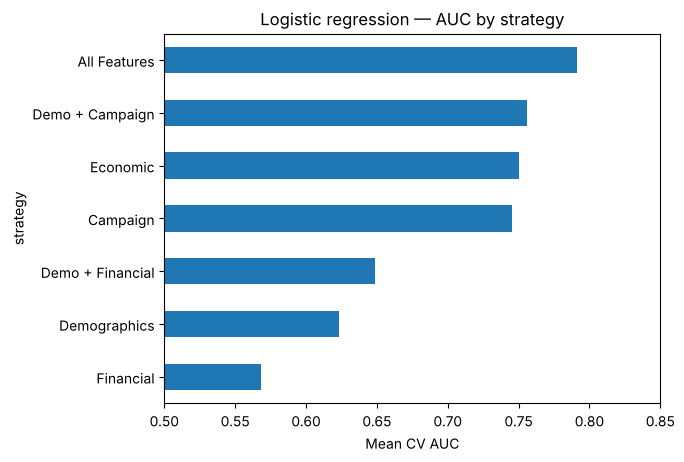

In [14]:
lr_results.sort_values('AUC').plot.barh(x='strategy', y='AUC', legend=False, xlim=(0.5, 0.85))
plt.xlabel('Mean CV AUC'); plt.title('Logistic regression — AUC by strategy'); plt.show()

### Discussion

**Answer the following:**
- Which feature strategy achieves the highest AUC? The highest sensitivity?
- Why is AUC a better metric than accuracy for this dataset?
- Do economic indicators add predictive value? Why might that be?
- Which strategy will you use going forward, and why?

- **Best AUC:** All Features (0.791). It also has the best sensitivity (0.22), though it's still low at the 0.5 threshold.
- **Why AUC:** every strategy has ~89–90% accuracy, even the ones that never predict a "yes" (Demographics and Financial have 0 sensitivity). Accuracy can't tell them apart. AUC measures how well the model *ranks* clients, which is exactly what you need to decide who to call first.
- **Economic indicators:** yes, a lot. With only 5 variables they score 0.750 AUC, more than demographics with 22. The context (interest rates, employment) decides whether people want to lock money in a deposit. When euribor is low, 25% subscribe; when it's high, 5%. The downside: it says *when* to call, not *who*.
- **Choice: All Features.** Highest AUC and sensitivity. With 41k rows, 52 variables aren't an overfitting risk, and each group adds something different.

---
## 4. Fitting the Selected Model

Fit the best strategy on the **full dataset** using `statsmodels` for detailed statistical output (p-values, confidence intervals).

### Task 4.1: Fit logistic regression with statsmodels

Use `sm.Logit()` with your selected features. Remember to add a constant with `sm.add_constant()`. Print the model summary.

**Hint:** Use `method='bfgs'` in `.fit()` — the default Newton method can fail with a "Singular matrix" error when features are near-collinear. Also cast features to float with `.astype(float)` before fitting.

In [15]:
# loan_unknown is identical to housing_unknown (same 990 clients) -> drop it or the Hessian is singular
SEL = [f for f in feature_strategies['All Features'] if f != 'loan_unknown']
X = sm.add_constant(df_encoded[SEL].astype(float))
result = sm.Logit(y, X).fit(method='bfgs', maxiter=2000, disp=0)
print(result.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                41188
Model:                          Logit   Df Residuals:                    41136
Method:                           MLE   Df Model:                           51
Date:                Thu, 22 Oct 2026   Pseudo R-squ.:                  0.2152
Time:                        14:55:48   Log-Likelihood:                -11379.
converged:                       True   LL-Null:                       -14499.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const                            -0.1609     34.329     -0.005      0.996     -67.445      67.124
age                               0.0010      0.002      0.450      0.652 

### Task 4.2: Interpret key coefficients and odds ratios

Extract the significant coefficients (p < 0.05), compute odds ratios ($e^{\beta}$), and interpret the most important features.

**Hint:** Use `np.exp(result.params)` for odds ratios. Filter by `result.pvalues < 0.05`.

In [16]:
sig = pd.DataFrame({'coef': result.params, 'odds_ratio': np.exp(result.params), 'p': result.pvalues})
sig = sig[(sig.p < 0.05) & (sig.index != 'const')].sort_values('odds_ratio', ascending=False)
sig.round(3)

,coef,odds_ratio,p
contacted_before,1.070,2.914,0.000
month_mar,0.966,2.628,0.000
poutcome_success,0.779,2.180,0.000
euribor3m,0.652,1.919,0.000
cons.price.idx,0.580,1.785,0.010
poutcome_nonexistent,0.438,1.550,0.000
job_retired,0.238,1.269,0.011
job_student,0.211,1.235,0.035
day_of_week_wed,0.141,1.151,0.014
nr.employed,-0.011,0.989,0.000


---
## 5. Model Evaluation

### Task 5.1: Confusion matrix and classification metrics

Using a threshold of 0.5:
1. Generate predicted classes from the model's predicted probabilities
2. Compute and print the confusion matrix
3. Calculate accuracy, sensitivity, specificity, and precision

In [17]:
p_lr = result.predict(X)
yhat_lr = (p_lr >= 0.5).astype(int)
print(confusion_matrix(y, yhat_lr))
acc_lr, sens_lr, spec_lr, prec_lr = metrics(y, yhat_lr)
print(f'Accuracy {acc_lr:.3f} | Sensitivity {sens_lr:.3f} | Specificity {spec_lr:.3f} | Precision {prec_lr:.3f}')

[[36037   511]
 [ 3587  1053]]
Accuracy 0.901 | Sensitivity 0.227 | Specificity 0.986 | Precision 0.673


### Task 5.2: ROC curve and AUC

Plot the ROC curve and compute the AUC score. Include:
- The ROC curve itself (blue)
- The diagonal baseline (red dashed)
- The AUC value in the legend

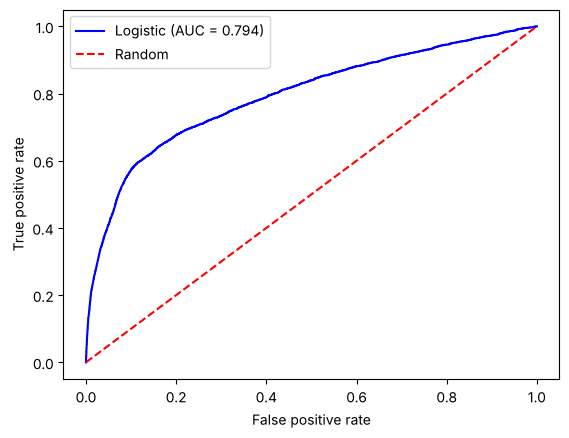

In [18]:
def plot_roc(curves):
    for name, (p, color) in curves.items():
        fpr, tpr, _ = roc_curve(y, p)
        plt.plot(fpr, tpr, color=color, label=f'{name} (AUC = {roc_auc_score(y, p):.3f})')
    plt.plot([0, 1], [0, 1], 'r--', label='Random')
    plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.legend(); plt.show()

auc_lr = roc_auc_score(y, p_lr)
plot_roc({'Logistic': (p_lr, 'blue')})

---
## 6. Lift Chart — Logistic Regression

A lift chart shows how much better the model is at identifying subscribers compared to random targeting.

### Task 6.1: Build the lift chart table

Steps:
1. Add predicted probabilities to the DataFrame
2. Sort by predicted probability (descending)
3. Assign deciles (1 = top 10%, 10 = bottom 10%)
4. For each decile, compute: observed subscriptions, cumulative observed, expected (random), cumulative expected, lift, difference

**Hint:** For decile assignment, use `(index // (n / 10)).astype(int) + 1` after sorting and resetting the index.

In [19]:
def lift_table(p):
    d = pd.DataFrame({'y': y.values, 'p': np.asarray(p)}).sort_values('p', ascending=False).reset_index(drop=True)
    d['decile'] = (d.index // (len(d) / 10)).astype(int) + 1
    t = d.groupby('decile').agg(n=('y', 'size'), observed=('y', 'sum'))
    t['cum_observed'] = t.observed.cumsum()
    t['expected'] = t.n * y.mean()
    t['cum_expected'] = t.expected.cumsum()
    t['lift'] = t.observed / t.expected
    t['cum_lift'] = t.cum_observed / t.cum_expected
    t['difference'] = t.cum_observed - t.cum_expected
    return t.round(2)

df_encoded['Predicted_Probability'] = p_lr
lift_lr = lift_table(p_lr)
lift_lr

,n,observed,cum_observed,expected,cum_expected,lift,cum_lift,difference
decile,,,,,,,,
1,4119,2028,2028,464.02,464.02,4.37,4.37,1563.98
2,4119,867,2895,464.02,928.05,1.87,3.12,1966.95
3,4119,380,3275,464.02,1392.07,0.82,2.35,1882.93
4,4119,278,3553,464.02,1856.09,0.60,1.91,1696.91
5,4119,254,3807,464.02,2320.11,0.55,1.64,1486.89
6,4118,217,4024,463.91,2784.02,0.47,1.45,1239.98
7,4119,181,4205,464.02,3248.05,0.39,1.29,956.95
8,4119,158,4363,464.02,3712.07,0.34,1.18,650.93
9,4119,141,4504,464.02,4176.09,0.30,1.08,327.91


### Task 6.2: Plot the cumulative lift chart

Create a plot with:
- X-axis: decile (1 to 10)
- Blue squares: model cumulative observed
- Red triangles (dashed): random cumulative expected
- Annotate the point of maximum difference

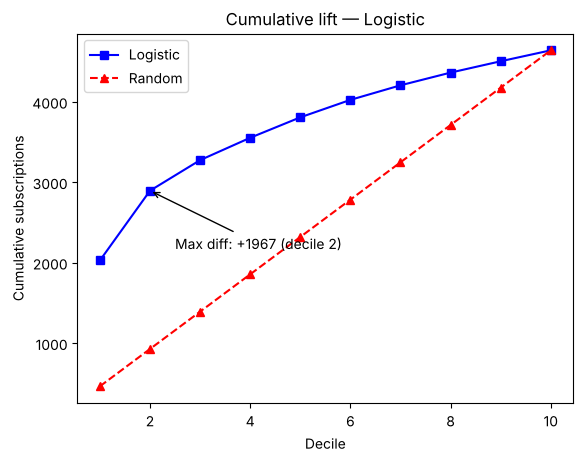

In [20]:
def plot_lift(tables, title):
    for name, (t, style) in tables.items():
        plt.plot(t.index, t.cum_observed, style, label=name)
    plt.plot(t.index, t.cum_expected, 'r^--', label='Random')
    if len(tables) == 1:
        best = t.difference.idxmax()
        plt.annotate(f'Max diff: +{t.difference[best]:.0f} (decile {best})', (best, t.cum_observed[best]),
                     xytext=(best + 0.5, t.cum_observed[best] * 0.75), arrowprops=dict(arrowstyle='->'))
    plt.xlabel('Decile'); plt.ylabel('Cumulative subscriptions'); plt.title(title); plt.legend(); plt.show()

plot_lift({'Logistic': (lift_lr, 'bs-')}, 'Cumulative lift — Logistic')

---
## 7. XGBoost Model

Now let's repeat the analysis with XGBoost and compare.

### Task 7.1: Cross-validate XGBoost across feature strategies

Repeat the cross-validation from Section 3, but using `XGBClassifier` instead of `LogisticRegression`. Use the same 10-fold CV setup.

**Hint:** Use `XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, eval_metric='logloss', random_state=42)`.

In [21]:
make_xgb = lambda: XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1,
                                 eval_metric='logloss', random_state=42)
xgb_results = cv_strategies(make_xgb)
xgb_results

,strategy,n_features,accuracy,sensitivity,specificity,AUC
0,Demographics,22,0.887,0.022,0.997,0.641
1,Financial,6,0.887,0.000,1.000,0.565
2,Campaign,19,0.899,0.209,0.987,0.766
3,Economic,5,0.890,0.193,0.979,0.794
4,Demo + Financial,28,0.887,0.020,0.997,0.664
5,Demo + Campaign,41,0.898,0.207,0.986,0.775
6,All Features,52,0.901,0.234,0.986,0.802


### Task 7.2: Fit the best XGBoost model and evaluate

Select the best feature strategy from CV results. Fit on the full dataset and evaluate:
1. Print the confusion matrix
2. Compute accuracy, sensitivity, specificity, and precision

In [22]:
SEL_XGB = feature_strategies[xgb_results.loc[xgb_results.AUC.idxmax(), 'strategy']]
xgb_model = make_xgb().fit(df_encoded[SEL_XGB], y)
p_xgb = xgb_model.predict_proba(df_encoded[SEL_XGB])[:, 1]
yhat_xgb = (p_xgb >= 0.5).astype(int)
print(confusion_matrix(y, yhat_xgb))
acc_xgb, sens_xgb, spec_xgb, prec_xgb = metrics(y, yhat_xgb)
print(f'Accuracy {acc_xgb:.3f} | Sensitivity {sens_xgb:.3f} | Specificity {spec_xgb:.3f} | Precision {prec_xgb:.3f}')

[[36043   505]
 [ 3486  1154]]
Accuracy 0.903 | Sensitivity 0.249 | Specificity 0.986 | Precision 0.696


### Task 7.3: Feature importance

Plot the **top 15** feature importances from the fitted XGBoost model as a horizontal bar chart.

**Hint:** Use `xgb_model.feature_importances_` and `np.argsort()` to get the top 15 indices.

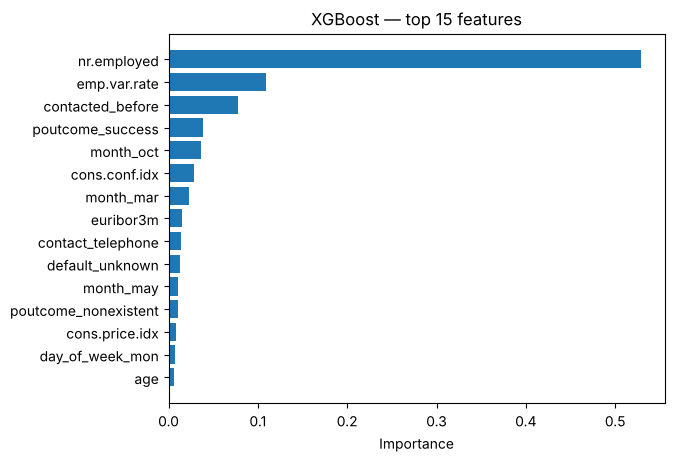

In [23]:
top = np.argsort(xgb_model.feature_importances_)[-15:]
plt.barh(np.array(SEL_XGB)[top], xgb_model.feature_importances_[top])
plt.xlabel('Importance'); plt.title('XGBoost — top 15 features'); plt.show()

### Task 7.4: ROC curve and AUC

Plot the ROC curve for the XGBoost model (green) with AUC in the legend.

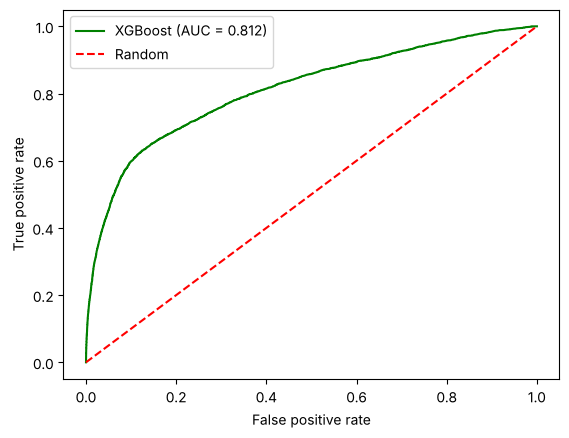

In [24]:
auc_xgb = roc_auc_score(y, p_xgb)
plot_roc({'XGBoost': (p_xgb, 'green')})

### Task 7.5: XGBoost Lift Chart

Repeat the lift chart analysis from Section 6, but using the XGBoost model's predicted probabilities. Build the table and plot the cumulative chart.

,n,observed,cum_observed,expected,cum_expected,lift,cum_lift,difference
decile,,,,,,,,
1,4119,2170,2170,464.02,464.02,4.68,4.68,1705.98
2,4119,835,3005,464.02,928.05,1.80,3.24,2076.95
3,4119,348,3353,464.02,1392.07,0.75,2.41,1960.93
4,4119,316,3669,464.02,1856.09,0.68,1.98,1812.91
5,4119,232,3901,464.02,2320.11,0.50,1.68,1580.89
6,4118,192,4093,463.91,2784.02,0.41,1.47,1308.98
7,4119,156,4249,464.02,3248.05,0.34,1.31,1000.95
8,4119,165,4414,464.02,3712.07,0.36,1.19,701.93
9,4119,138,4552,464.02,4176.09,0.30,1.09,375.91


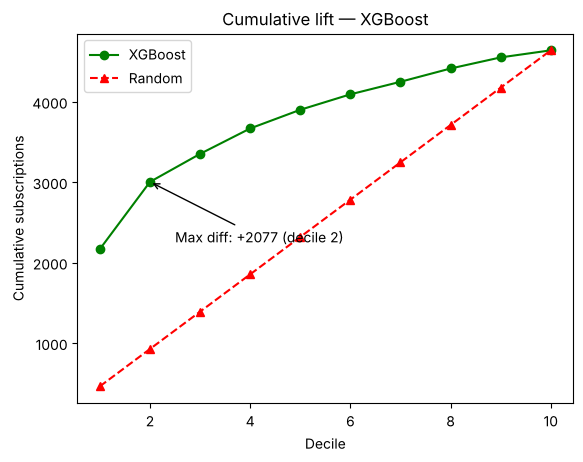

In [25]:
lift_xgb = lift_table(p_xgb)
display(lift_xgb)
plot_lift({'XGBoost': (lift_xgb, 'go-')}, 'Cumulative lift — XGBoost')

---
## 8. Model Comparison

### Task 8.1: Summary comparison table

Create a summary table comparing accuracy, sensitivity, specificity, precision, and AUC for both models.

In [26]:
pd.DataFrame({'Logistic': [acc_lr, sens_lr, spec_lr, prec_lr, auc_lr],
              'XGBoost': [acc_xgb, sens_xgb, spec_xgb, prec_xgb, auc_xgb]},
             index=['accuracy', 'sensitivity', 'specificity', 'precision', 'AUC']).round(3)

,Logistic,XGBoost
accuracy,0.901,0.903
sensitivity,0.227,0.249
specificity,0.986,0.986
precision,0.673,0.696
AUC,0.794,0.812


### Task 8.2: Overlaid ROC curves

Plot both ROC curves on the same figure: Logistic Regression (blue), XGBoost (green), Random (red dashed).

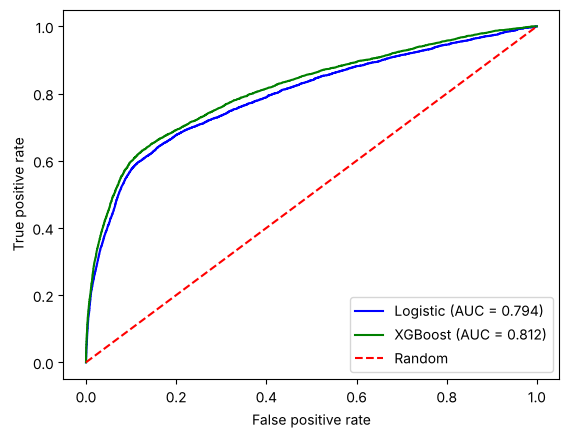

In [27]:
plot_roc({'Logistic': (p_lr, 'blue'), 'XGBoost': (p_xgb, 'green')})

### Task 8.3: Overlaid cumulative lift charts

Plot both cumulative lift curves on the same figure: Logistic Regression (blue squares), XGBoost (green circles), Random (red triangles).

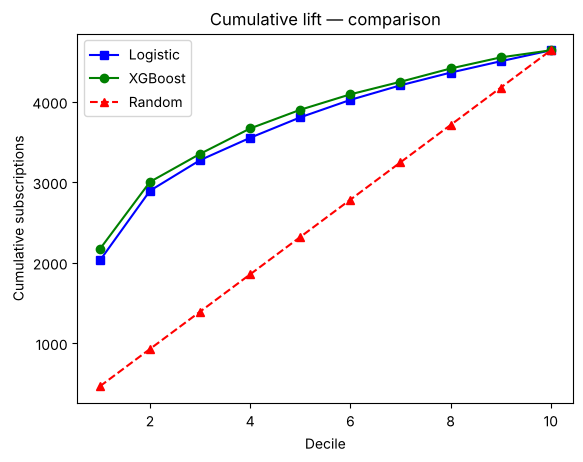

In [28]:
plot_lift({'Logistic': (lift_lr, 'bs-'), 'XGBoost': (lift_xgb, 'go-')}, 'Cumulative lift — comparison')

### Discussion

**Answer the following:**
- Which model performs better overall? Consider accuracy, AUC, sensitivity, and specificity.
- Does XGBoost provide a meaningful improvement over logistic regression for this dataset?
- What are the trade-offs between using logistic regression vs XGBoost? Think about interpretability, ease of explanation to stakeholders, and predictive power.
- Which model would you recommend to a Head of Marketing, and why?

- **Who wins?** XGBoost, slightly: AUC 0.812 vs 0.794, sensitivity 0.25 vs 0.23, precision 0.70 vs 0.67, same specificity. Its lift is also a bit better (top 10%: 4.7× vs 4.4×).
- **Is it meaningful?** Not much. In CV the gap is ~1 point of AUC (0.802 vs 0.791), and both lift curves almost overlap. It's worth a few hundred extra subscriptions on 41k clients, but it doesn't change the strategy.
- **Trade-offs:** logit gives clear, defensible coefficients ("calling by mobile instead of landline almost doubles the odds", "if they already said yes once, ×2"). XGBoost captures non-linearities (age, macro context) without you having to model them, but it's a black box: it says *what matters*, not *in which direction*.
- **Recommendation:** for a Head of Marketing, **the logistic regression**. It's almost as good, it can be explained on one slide, and it's easy to audit. If the bank is going to operationalise the scoring at scale, use XGBoost to rank and the logit to explain.

---
## 9. Designing a Targeting Strategy

Using your lift charts, model evaluation, and exploratory analysis, design a data-driven targeting strategy.

**Answer the following:**
- **How many customers should be targeted?** Justify with the lift chart — at which decile is the maximum difference between cumulative observed and expected?
- **What customer profile should be targeted?** Use the logistic regression coefficients and XGBoost feature importance to describe the ideal target.
- **What is the expected uplift vs random targeting?** Quantify using the lift chart numbers.
- **What are the risks?** What happens if the model is wrong (false positives = wasted calls; false negatives = missed opportunities)?
- **Which model would you present to the Head of Marketing?** Justify your choice.

- **How many:** the **top 20%** (~8,200 clients). The maximum gap vs random is in decile 2 (+1,967 subscriptions with logit, +2,077 with XGBoost). From decile 3 on, each group converts *below* the average, so calling them costs more than it brings in.
- **Profile:** clients who were already contacted and especially those who said yes before (×2–3 odds), contacted **by mobile** (landline ×0.56), students and retirees. Avoid the third and later calls in the same campaign (each extra call: −4%). Timing matters as much as profile: periods with low euribor and falling employment, and months like March (×2.6) rather than May or November. In XGBoost, macro variables (nr.employed, emp.var.rate) dominate the importance.
- **Uplift:**
  - Top 10% converts at 49% vs 11% (lift 4.4).
  - Top 20% captures 62% of all subscriptions (2,895 of 4,640) while calling only 1 in 5 clients, vs 928 if random: **3.1× more**.
- **Risks:** *false positives* are wasted calls and annoyed customers. In the top 20%, ~65% of calls still end in a "no". *False negatives*: the 38% of subscribers outside the top 20% are lost. At 0.5 the model only catches 23% of them, so for operations you should use the ranking or a lower threshold, not 0.5. Also, the economic variables change over time, so the model has to be retrained when the cycle shifts, and it should be validated with a control group.
- **Which model:** **logistic regression** for the Head of Marketing. It delivers 95% of XGBoost's performance with an explanation anyone can follow. XGBoost can stay as the operational scoring engine if the extra ~1 point of AUC is worth it.